# 01 - Data Cleaning & Feature Engineering
**Proyek:** Rental Price Predictor & Deal Spotter - Kos di Kota Depok

Notebook ini mengubah `data/raw/listings.jsonl` (hasil scraping) menjadi `data/processed/listings_clean.csv` yang siap dipakai untuk EDA dan modeling.

**Langkah:**
1. Filter: buang listing yang bukan kos di Kota Depok atau koordinatnya salah
2. Normalisasi kecamatan dan tipe kos
3. Parsing ukuran kamar menjadi luas m²
4. Fasilitas menjadi kolom 0/1
5. Fitur lokasi: jarak ke UI dan stasiun KRL
6. Fitur kualitas listing: umur update (*staleness*), umur bangunan, dan lainnya
7. Simpan hasil + pengecekan kualitas

In [1]:
import json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

RAW = Path("../data/raw/listings.jsonl")
OUT = Path("../data/processed/listings_clean.csv")
OUT.parent.mkdir(parents=True, exist_ok=True)

# --- Parameter yang bisa diubah ---
STALE_DAYS = 365                 # listing dianggap "segar" jika diupdate <= 365 hari sebelum scraping
LUAS_MIN, LUAS_MAX = 4, 40       # luas kamar (m2) di luar rentang ini dianggap tidak valid
BBOX = dict(lat=(-6.55, -6.25), lon=(106.70, 106.95))   # kotak kasar Kota Depok
KECAMATAN_DEPOK = {
    "beji": "Beji", "cimanggis": "Cimanggis", "cinere": "Cinere", "cilodong": "Cilodong",
    "cipayung": "Cipayung", "limo": "Limo", "pancoranmas": "Pancoran Mas",
    "sawangan": "Sawangan", "sukmajaya": "Sukmajaya", "tapos": "Tapos", "bojongsari": "Bojongsari",
}

## 1. Muat data

In [2]:
raw = pd.DataFrame([json.loads(l) for l in RAW.read_text(encoding="utf-8").splitlines() if l.strip()])
print(raw.shape, "| URL unik:", raw["url"].nunique(), "| ID unik:", raw["_id"].nunique())
raw.head(3)

(2176, 47) | URL unik: 2176 | ID unik: 2176


,url,scraped_at,_id,slug,room_title,area_city,area_subdistrict,gender,latitude,longitude,size,price_daily,price_weekly,price_monthly,price_quarterly,price_semiannualy,price_yearly,price_tag,min_month,fac_room,fac_share,fac_bath,fac_near,fac_park,kos_rule,rating,review_count,view_count,love_count,available_room,updated_at,not_updated,online,is_inactive_owner,building_year,is_booking,booking_type,level_name,is_singgahsini,is_apik,is_elite,goldplus,number_success_kos_trx,transaction_count,is_flash_sale,verification_status,photo_count
0,https://mamikos.com/room/kost-depok-kost-campu...,2026-10-19 20:41:11,76043446,kost-depok-kost-campur-eksklusif-kost-adia-suk...,Kost Adia Sukmajaya Depok,Kota Depok,Sukma Jaya,0,-6.396025,106.851860,3x4,0,0,1200000,0,0,0,eksklusif,NaN,"[Kasur, Lemari / Storage, AC]","[R. Tamu, Dapur, R. Cuci, Balcon, WiFi]","[K. Mandi Dalam, Kloset Duduk]","[Warung makan / Rumah makan, Mini market / War...","[Parkir Mobil, Parkir Motor, Parkir Sepeda]",[],0.0,0,6455.0,181,0,2021-11-23 02:15:26,True,Lama Tidak Update,False,2019.0,True,[bulanan],Regular,False,False,False,0,1,1,False,"{'is_verified_address': True, 'is_verified_pho...",39
1,https://mamikos.com/room/kost-depok-kost-campu...,2026-10-19 20:41:15,11875129,kost-depok-kost-campur-eksklusif-kost-akses-ui...,Kost Akses UI 42 Cimanggis Depok,Kota Depok,Cimanggis,0,-6.354404,106.839578,3x2,0,0,1100000,0,0,12100000,eksklusif,Min. 3 Bln,"[Kasur, Lemari / Storage, AC, Meja, Cleaning s...","[R. Jemur, R. Cuci, Balcon, Kartu Akses Masuk]","[K. Mandi Dalam, Shower, Kloset Jongkok]","[Warung makan / Rumah makan, Mini market / War...",[Parkir Motor],[],0.0,0,11792.0,130,2,2023-09-25 13:56:20,False,Lama Tidak Update,True,NaN,True,[bulanan],Regular,False,False,False,0,1,0,False,"{'is_verified_address': True, 'is_verified_pho...",4
2,https://mamikos.com/room/kost-depok-kost-campu...,2026-10-19 20:41:20,82195331,kost-depok-kost-campur-eksklusif-kost-amara-51...,Kost Amara 51 Residen Beji Depok,Kota Depok,Beji,0,-6.367841,106.817493,3x4,130000,900000,1800000,0,0,0,eksklusif,NaN,[AC],"[WiFi, TV]","[K. Mandi Dalam, Air panas]",[],[Parkir Mobil],[],0.0,0,16059.0,282,0,2023-10-11 10:20:09,True,Lama Tidak Update,True,2015.0,True,[bulanan],Regular,False,False,False,0,0,0,False,"{'is_verified_address': True, 'is_verified_pho...",3


## 2. Filter listing
Setiap langkah pembuangan dicatat supaya jumlahnya bisa dilaporkan di README.

In [3]:
df = raw.drop_duplicates(subset="_id").copy()
drop_log = [("Duplikat ID", len(raw) - len(df))]

def drop_where(df, mask, alasan):
    drop_log.append((alasan, int(mask.sum())))
    return df[~mask].copy()

# a) Bukan kos (rumah/kontrakan/apartemen) berdasarkan judul
df = drop_where(df, df["room_title"].str.contains(r"^\s*(?:rumah|kontrakan|apartemen)\b", case=False, regex=True),
                "Bukan kos (rumah/kontrakan/apartemen)")

# b) Kecamatan bukan bagian Kota Depok (mis. Cilandak, Cibinong)
def norm_kec(s):
    s = re.sub(r"^kecamatan\s+", "", str(s).strip().lower())
    return s.replace(" ", "")
df["kec_key"] = df["area_subdistrict"].map(norm_kec)
df = drop_where(df, ~df["kec_key"].isin(KECAMATAN_DEPOK), "Kecamatan bukan Kota Depok")
df["kecamatan"] = df["kec_key"].map(KECAMATAN_DEPOK)

# c) Koordinat di luar kotak Depok (salah input)
out_bbox = ~df["latitude"].between(*BBOX["lat"]) | ~df["longitude"].between(*BBOX["lon"])
df = drop_where(df, out_bbox, "Koordinat di luar Depok")

# d) Harga tidak valid
df = drop_where(df, df["price_monthly"].fillna(0) <= 0, "Harga bulanan kosong/0")

pd.DataFrame(drop_log, columns=["Alasan", "Jumlah dibuang"]).assign(
    Sisa=lambda x: len(raw) - x["Jumlah dibuang"].cumsum())

,Alasan,Jumlah dibuang,Sisa
0,Duplikat ID,0,2176
1,Bukan kos (rumah/kontrakan/apartemen),107,2069
2,Kecamatan bukan Kota Depok,6,2063
3,Koordinat di luar Depok,4,2059
4,Harga bulanan kosong/0,0,2059


## 3. Tipe kos
Kode `gender` dicocokkan dengan kata kunci di slug URL: **0 = campur, 1 = putra, 2 = putri**. Ada sekitar 50 listing yang kode dan slug-nya bertentangan, jadi diberi penanda `tipe_konflik`.

In [4]:
df["tipe_kos"] = df["gender"].map({0: "campur", 1: "putra", 2: "putri"})

def tipe_dari_slug(s):
    for k in ("putra", "putri", "campur"):
        if f"kost-{k}-" in s: return k
    return None
df["tipe_slug"] = df["slug"].map(tipe_dari_slug)
df["tipe_konflik"] = (df["tipe_slug"].notna() & (df["tipe_slug"] != df["tipe_kos"])).astype(int)

print(pd.crosstab(df["tipe_kos"], df["tipe_slug"].fillna("tak terdeteksi")))
print("Konflik kode vs slug:", df["tipe_konflik"].sum())

tipe_slug  campur  putra  putri
tipe_kos                       
campur        740      0      3
putra          12    400      6
putri          29      1    868
Konflik kode vs slug: 51


## 4. Luas kamar
Kolom `size` berupa teks bebas: `3x4`, `3 x 4`, `20m2x`, `3x2,5m`, `3x3, 4x3`, dan seterusnya. Dipakai pola yang mengambil pasangan angka pertama.

In [5]:
def parse_luas(s):
    t = str(s).lower().replace("×", "x").replace("*", "x")
    t = re.sub(r"(\d),(\d)", r"\1.\2", t)                    # 2,5 -> 2.5
    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:m|meter)?\s*x\s*(\d+(?:\.\d+)?)", t)  # panjang x lebar
    if m: return float(m[1]) * float(m[2])
    m = re.search(r"(\d+(?:\.\d+)?)\s*m2", t)               # "20m2"
    if m: return float(m[1])
    return np.nan

df["luas_raw"] = df["size"].map(parse_luas)
df["luas_m2"] = df["luas_raw"].where(df["luas_raw"].between(LUAS_MIN, LUAS_MAX))
print("Tidak terparse:", df["luas_raw"].isna().sum(),
      "| di luar rentang valid:", (df["luas_raw"].notna() & df["luas_m2"].isna()).sum(),
      "| luas valid:", df["luas_m2"].notna().sum())
df["luas_m2"].describe()

Tidak terparse: 1 | di luar rentang valid: 21 | luas valid: 2037


count    2037.000000
mean       12.742842
std         5.569219
min         4.000000
25%         9.000000
50%        12.000000
75%        12.000000
max        40.000000
Name: luas_m2, dtype: float64

## 5. Fasilitas menjadi kolom 0/1
Nama fasilitas tidak seragam (`R.Cuci` vs `R. Cuci`, `Air Jernih` vs `air jernih`), jadi dinormalisasi dulu (huruf kecil, buang simbol), lalu dicocokkan **persis**. Pencocokan substring tidak dipakai karena ada nilai seperti "Tidak ada Kasur". Kolom `fac_share` kadang berbentuk dict, jadi diambil `.values()`.

In [6]:
def norm_fac(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())
def as_list(x): return list(x.values()) if isinstance(x, dict) else (x or [])

def fac_set(row):
    s = set()
    for col in ("fac_room", "fac_share", "fac_bath", "fac_park"):
        s.update(norm_fac(f) for f in as_list(row[col]))
    return s
df["_fac"] = df.apply(fac_set, axis=1)

FLAGS = {
    "ac": {"ac"}, "kipas_angin": {"kipasangin"}, "kasur": {"kasur"},
    "lemari": {"lemaristorage", "lemaripakaian"}, "meja": {"meja"}, "kursi": {"kursi"},
    "tv": {"tv"}, "kulkas": {"kulkas", "kulkasbersama"}, "wifi": {"wifi"},
    "km_dalam": {"kmandidalam"}, "km_luar": {"kmandiluar"}, "air_panas": {"airpanas"},
    "shower": {"shower"}, "kloset_duduk": {"klosetduduk"},
    "dapur": {"dapur", "dapurbersama", "dapurpribadi"}, "cctv": {"cctv"},
    "pengurus_penjaga": {"penguruskos", "penjagakos"},
    "laundry_cuci": {"laundry", "mesincuci", "rcuci"},
    "parkir_mobil": {"parkirmobil"}, "cleaning_service": {"cleaningservice"},
    "jendela": {"jendela"},
}
for name, keys in FLAGS.items():
    df[f"f_{name}"] = df["_fac"].map(lambda s, k=keys: int(bool(s & k)))

df["n_fasilitas"] = df["_fac"].map(len)
df["n_fasilitas_sekitar"] = df["fac_near"].map(lambda x: len(as_list(x)))
fac_cols = [c for c in df.columns if c.startswith("f_")]
df[fac_cols].mean().sort_values(ascending=False).round(3)

f_kasur               0.831
f_lemari              0.760
f_km_dalam            0.731
f_dapur               0.715
f_jendela             0.647
f_wifi                0.629
f_kloset_duduk        0.540
f_meja                0.534
f_pengurus_penjaga    0.509
f_shower              0.495
f_kursi               0.439
f_ac                  0.429
f_kulkas              0.403
f_cctv                0.386
f_laundry_cuci        0.341
f_parkir_mobil        0.335
f_km_luar             0.324
f_tv                  0.221
f_kipas_angin         0.205
f_cleaning_service    0.091
f_air_panas           0.075
dtype: float64

## 6. Fitur lokasi
Jarak (haversine, km) ke **UI** dan ke **stasiun KRL terdekat**. Titik acuan di bawah adalah koordinat **perkiraan**. Cek ulang di Google Maps dan sesuaikan kalau perlu.

In [7]:
POI = {   # (lat, lon) - PERKIRAAN, verifikasi di Google Maps
    "UI":               (-6.3624, 106.8272),
    "Stasiun UI":       (-6.3608, 106.8317),
    "Stasiun Pondok Cina": (-6.3693, 106.8326),
    "Stasiun Depok Baru":  (-6.3911, 106.8186),
    "Stasiun Depok":       (-6.4045, 106.8181),
}
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df["jarak_ui_km"] = haversine_km(df["latitude"], df["longitude"], *POI["UI"])
stasiun = [k for k in POI if k.startswith("Stasiun")]
d_st = np.column_stack([haversine_km(df["latitude"], df["longitude"], *POI[k]) for k in stasiun])
df["jarak_krl_km"] = d_st.min(axis=1)
df["stasiun_terdekat"] = [stasiun[i] for i in d_st.argmin(axis=1)]
df[["jarak_ui_km", "jarak_krl_km"]].describe().round(2)

,jarak_ui_km,jarak_krl_km
count,2059.00,2059.00
mean,3.85,3.01
std,2.83,2.55
min,0.04,0.01
25%,1.25,1.02
50%,3.16,1.68
75%,5.78,5.47
max,12.76,11.35


## 7. Fitur kualitas listing
- **`umur_update_hari`**: selisih tanggal scraping dan `updated_at`. Penanda bawaan Mamikos (`online`, `not_updated`) tidak konsisten, jadi dihitung sendiri.
- **`is_fresh`**: diupdate dalam `STALE_DAYS` hari terakhir. Listing basi mungkin memuat harga yang sudah tidak berlaku.
- **`umur_bangunan`**: dari `building_year`. Nilai 0 atau tidak masuk akal dijadikan NaN.
- **`min_bulan`**: minimal sewa dalam bulan (`Min. 1 Th` = 12; `Min. 1 Hari` = 0).

In [8]:
df["scraped_at"] = pd.to_datetime(df["scraped_at"])
df["updated_at"] = pd.to_datetime(df["updated_at"])
df["umur_update_hari"] = (df["scraped_at"].dt.normalize() - df["updated_at"].dt.normalize()).dt.days
df["is_fresh"] = (df["umur_update_hari"] <= STALE_DAYS).astype(int)

THIS_YEAR = int(df["scraped_at"].dt.year.max())
by = df["building_year"].where(df["building_year"].between(1990, THIS_YEAR))
df["umur_bangunan"] = THIS_YEAR - by

def parse_min_bulan(s):
    if not isinstance(s, str): return np.nan
    m = re.search(r"(\d+)\s*(bln|th|hari)", s.lower())
    if not m: return np.nan
    n, u = int(m[1]), m[2]
    return n if u == "bln" else n * 12 if u == "th" else 0
df["min_bulan"] = df["min_month"].map(parse_min_bulan)

df["ada_ulasan"] = (df["review_count"].fillna(0) > 0).astype(int)
df["is_goldplus"] = (df["goldplus"].fillna(0) > 0).astype(int)
df["is_verified_kost"] = df["verification_status"].map(lambda d: int(bool(d.get("is_verified_kost"))) if isinstance(d, dict) else 0)
df["is_eksklusif"] = (df["price_tag"] == "eksklusif").astype(int)

print("Segar (<= %d hari): %d dari %d" % (STALE_DAYS, df["is_fresh"].sum(), len(df)))
df["umur_update_hari"].describe().round(0)

Segar (<= 365 hari): 1080 dari 2059


count    2059.0
mean      533.0
std       583.0
min         0.0
25%        60.0
50%       316.0
75%       840.0
max      3027.0
Name: umur_update_hari, dtype: float64

## 8. Target dan kolom akhir
`price_daily/weekly/quarterly/semiannualy/yearly` **tidak** dibawa ke data akhir. Harga-harga itu turunan dari harga bulanan, jadi memasukkannya ke model akan menjadi *data leakage*.

In [9]:
df["harga_bulanan"] = df["price_monthly"].astype(int)
df["log_harga"] = np.log(df["harga_bulanan"])

FINAL = (["_id", "url", "room_title", "kecamatan", "area_city", "latitude", "longitude",
          "tipe_kos", "tipe_konflik", "price_tag", "is_eksklusif", "level_name",
          "harga_bulanan", "log_harga",
          "luas_m2", "luas_raw", "jarak_ui_km", "jarak_krl_km", "stasiun_terdekat",
          "n_fasilitas", "n_fasilitas_sekitar"] + fac_cols +
         ["umur_update_hari", "is_fresh", "umur_bangunan", "min_bulan", "available_room",
          "rating", "review_count", "ada_ulasan", "view_count", "love_count",
          "is_goldplus", "is_verified_kost", "photo_count", "updated_at", "scraped_at"])
clean = df[FINAL].rename(columns={"_id": "id", "room_title": "nama", "area_city": "kota_raw",
                                  "available_room": "kamar_tersedia", "rating": "rating",
                                  "review_count": "jumlah_ulasan", "view_count": "jumlah_dilihat",
                                  "love_count": "jumlah_disukai", "photo_count": "jumlah_foto",
                                  "price_tag": "kelas_harga", "level_name": "level_mamikos"}).reset_index(drop=True)

# --- Pengecekan kualitas ---
assert clean["id"].is_unique
assert clean[["latitude", "longitude", "harga_bulanan", "kecamatan", "tipe_kos"]].notna().all().all()
assert clean["harga_bulanan"].gt(0).all()
print("OK:", clean.shape)
clean.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).round(3).rename("proporsi NaN")

OK: (2059, 57)


min_bulan         0.731
umur_bangunan     0.144
jumlah_dilihat    0.034
luas_m2           0.011
luas_raw          0.000
Name: proporsi NaN, dtype: float64

In [10]:
clean.to_csv(OUT, index=False, encoding="utf-8")
print("Tersimpan:", OUT.resolve(), "|", len(clean), "baris,", clean.shape[1], "kolom")

Tersimpan: /home/claude/proj/data/processed/listings_clean.csv | 2059 baris, 57 kolom


## 9. Pemeriksaan cepat (bahan EDA)
Ini baru gambaran awal. Analisis penuh ada di `02_eda.ipynb`.

In [11]:
ringkas = (clean.groupby("kecamatan")["harga_bulanan"]
           .agg(n="count", median="median", rata2="mean").round(0).sort_values("median", ascending=False))
ringkas

,n,median,rata2
kecamatan,,,
Cinere,262,1255000.0,1304899.0
Sukmajaya,137,1100000.0,1207073.0
Beji,856,1000500.0,1170136.0
Tapos,76,1000000.0,1067434.0
Limo,112,1000000.0,1119223.0
Cimanggis,256,950000.0,1101483.0
Cilodong,54,925000.0,1007870.0
Pancoran Mas,130,900000.0,1037731.0
Cipayung,24,900000.0,1025000.0


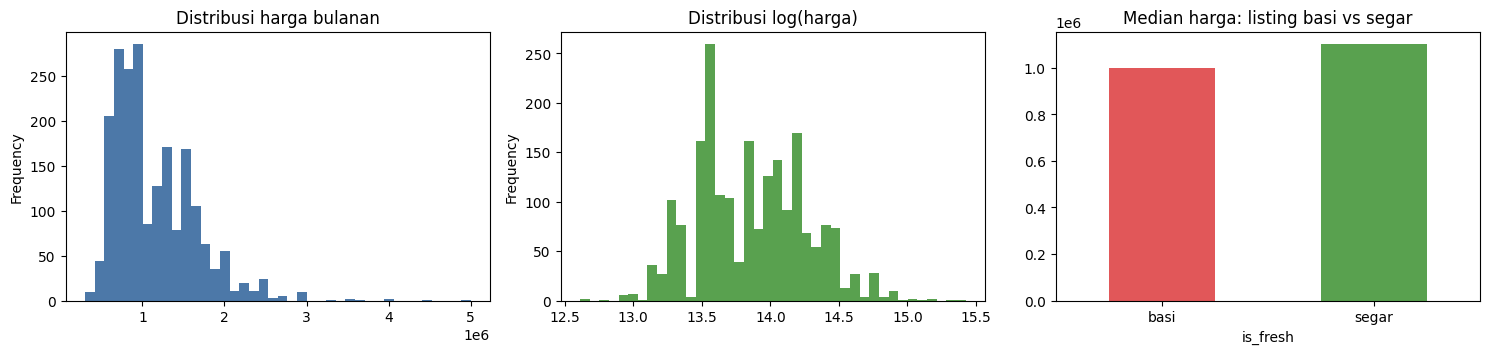

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
clean["harga_bulanan"].plot.hist(bins=40, ax=ax[0], color="#4c78a8"); ax[0].set_title("Distribusi harga bulanan")
clean["log_harga"].plot.hist(bins=40, ax=ax[1], color="#59a14f"); ax[1].set_title("Distribusi log(harga)")
clean.groupby("is_fresh")["harga_bulanan"].median().rename({0: "basi", 1: "segar"}).plot.bar(ax=ax[2], color=["#e15759", "#59a14f"])
ax[2].set_title("Median harga: listing basi vs segar"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [13]:
clean[["log_harga", "luas_m2", "jarak_ui_km", "jarak_krl_km", "n_fasilitas", "umur_update_hari"]].corr(method="spearman").round(2)

,log_harga,luas_m2,jarak_ui_km,jarak_krl_km,n_fasilitas,umur_update_hari
log_harga,1.00,0.19,-0.02,0.08,0.37,-0.10
luas_m2,0.19,1.00,0.03,0.02,-0.06,0.06
jarak_ui_km,-0.02,0.03,1.00,0.82,-0.08,0.06
jarak_krl_km,0.08,0.02,0.82,1.00,-0.02,0.04
n_fasilitas,0.37,-0.06,-0.08,-0.02,1.00,-0.27
umur_update_hari,-0.10,0.06,0.06,0.04,-0.27,1.00
